# Xarray in 10 Minutes

## A quick tutorial for beginners

**Goal:** Learn how to create, inspect, select, calculate, and plot labeled multidimensional data with `xarray`.

By the end, you will be able to:

1. Explain the difference between a `DataArray` and a `Dataset`.
2. Select data using coordinate labels.
3. Calculate averages across named dimensions.
4. Make a quick plot.

This notebook uses a small, self-contained weather dataset, so no download is required.

## 1. Import the packages — 1 minute

`xarray` works especially well with NumPy, pandas, Matplotlib, and NetCDF data.

In [2]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

print("xarray version:", xr.__version__)

xarray version: 2026.7.0


## 2. Create a small weather dataset — 2 minutes

An xarray object stores:

- **data variables**: the measured values, such as temperature;
- **dimensions**: the axes of the data, such as time, latitude, and longitude;
- **coordinates**: labels along those dimensions;
- **attributes**: metadata, including units and descriptions.

A `DataArray` contains one labeled variable. A `Dataset` can contain several variables that share coordinates.

In [3]:
# Coordinate labels
times = pd.date_range("2026-09-01", periods=4, freq="6h")
latitudes = np.array([35.0, 40.0, 45.0])
longitudes = np.array([-90.0, -85.0, -80.0, -75.0])

# Make reproducible synthetic temperature data in kelvin.
rng = np.random.default_rng(seed=42)
temperature = 288 + 5 * rng.random(
    (len(times), len(latitudes), len(longitudes))
)

ds = xr.Dataset(
    data_vars={
        "temperature": (
            ("time", "latitude", "longitude"),
            temperature,
            {
                "long_name": "2 m air temperature",
                "units": "K",
            },
        )
    },
    coords={
        "time": times,
        "latitude": latitudes,
        "longitude": longitudes,
    },
    attrs={"description": "Small synthetic weather dataset"},
)

ds

<xarray.Dataset> Size: 472B
Dimensions:      (time: 4, latitude: 3, longitude: 4)
Coordinates:
  * time         (time) datetime64[us] 32B 2026-09-01 ... 2026-09-01T18:00:00
  * latitude     (latitude) float64 24B 35.0 40.0 45.0
  * longitude    (longitude) float64 32B -90.0 -85.0 -80.0 -75.0
Data variables:
    temperature  (time, latitude, longitude) float64 384B 291.9 290.2 ... 289.4
Attributes:
    description:  Small synthetic weather dataset

### Read the dataset summary

In the output above, find:

- the three dimensions;
- their sizes;
- the `temperature` variable;
- the temperature units.

Use square brackets to extract one variable as a `DataArray`.

In [4]:
temperature_da = ds["temperature"]

print(type(ds))
print(type(temperature_da))
print("Dimensions:", temperature_da.dims)
print("Shape:", temperature_da.shape)

temperature_da

<class 'xarray.core.dataset.Dataset'>
<class 'xarray.core.dataarray.DataArray'>
Dimensions: ('time', 'latitude', 'longitude')
Shape: (4, 3, 4)


<xarray.DataArray 'temperature' (time: 4, latitude: 3, longitude: 4)> Size: 384B
array([[[291.86978024, 290.1943922 , 292.2929896 , 291.48684015],
        [288.47088674, 292.87811176, 291.80569851, 291.93032153],
        [288.64056816, 290.25192969, 289.85399012, 292.63382494]],

       [[291.2193256 , 292.11380807, 290.21707099, 289.13619361],
        [290.77292394, 288.31908628, 292.13815586, 291.158322  ],
        [291.7904387 , 289.77262984, 292.85349012, 292.46560561]],

       [[291.89191749, 288.97319354, 290.33360502, 288.21901883],
        [288.77144746, 291.41524477, 291.72381078, 292.83754866],
        [289.62912679, 289.85229853, 290.34777906, 288.9473568 ]],

       [[288.64960753, 290.37852463, 289.13454675, 291.34906997],
        [290.18575959, 292.16339098, 291.50132551, 289.56183321],
        [292.16129901, 292.02382179, 289.9373919 , 289.44164052]]])
Coordinates:
  * time       (time) datetime64[us] 32B 2026-09-01 ... 2026-09-01T18:00:00
  * latitude   (latitude) float64 24B 35.0 40.0 45.0
  * longitude  (longitude) float64 32B -90.0 -85.0 -80.0 -75.0
Attributes:
    long_name:  2 m air temperature
    units:      K

## 3. Select data — 2 minutes

Two common selection methods are:

- `.isel()` — select by integer position;
- `.sel()` — select by coordinate label.

Using coordinate labels often makes scientific code easier to read.

In [5]:
# First time step, selected by position
first_time = ds["temperature"].isel(time=0)

# Temperature at the grid point nearest 41°N, 86°W
near_location = ds["temperature"].sel(
    latitude=41.0,
    longitude=-86.0,
    method="nearest",
)

print("First map shape:", first_time.shape)
print("Coordinates actually selected:")
print(" latitude =", float(near_location.latitude.values))
print(" longitude =", float(near_location.longitude.values))

near_location

First map shape: (3, 4)
Coordinates actually selected:
 latitude = 40.0
 longitude = -85.0


<xarray.DataArray 'temperature' (time: 4)> Size: 32B
array([292.87811176, 288.31908628, 291.41524477, 292.16339098])
Coordinates:
  * time       (time) datetime64[us] 32B 2026-09-01 ... 2026-09-01T18:00:00
    latitude   float64 8B 40.0
    longitude  float64 8B -85.0
Attributes:
    long_name:  2 m air temperature
    units:      K

## 4. Calculate with named dimensions — 2 minutes

With xarray, calculations can refer to dimension names instead of axis numbers.

Below, we convert kelvin to degrees Celsius and calculate a spatial mean at each time.

In [6]:
# Xarray preserves the coordinates during arithmetic.
ds["temperature_c"] = ds["temperature"] - 273.15
ds["temperature_c"].attrs = {
    "long_name": "2 m air temperature",
    "units": "°C",
}

# Average over latitude and longitude, leaving a time series.
regional_mean = ds["temperature_c"].mean(
    dim=["latitude", "longitude"]
)

regional_mean

<xarray.DataArray 'temperature_c' (time: 4)> Size: 32B
array([17.8757778 , 17.84642088, 17.09519564, 17.39068428])
Coordinates:
  * time     (time) datetime64[us] 32B 2026-09-01 ... 2026-09-01T18:00:00
Attributes:
    long_name:  2 m air temperature
    units:      °C

## 5. Plot the data — 1 minute

Xarray uses the coordinate labels automatically when plotting.

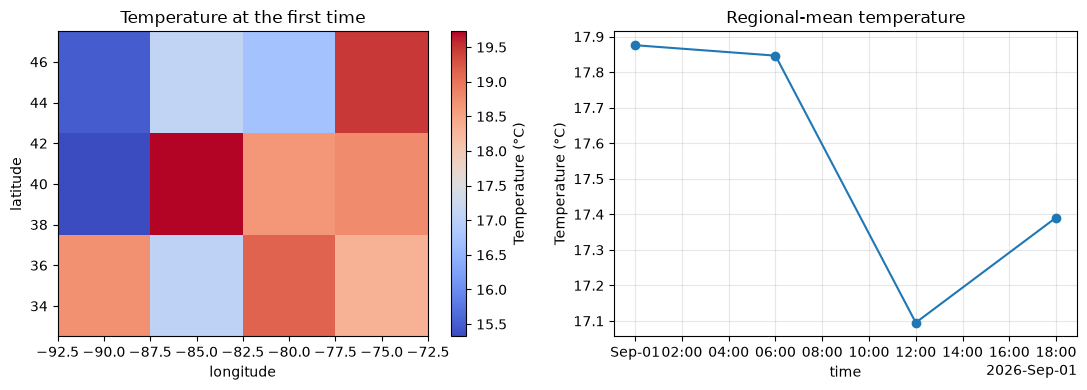

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ds["temperature_c"].isel(time=0).plot(
    ax=axes[0],
    cmap="coolwarm",
    cbar_kwargs={"label": "Temperature (°C)"},
)
axes[0].set_title("Temperature at the first time")

regional_mean.plot(ax=axes[1], marker="o")
axes[1].set_title("Regional-mean temperature")
axes[1].set_ylabel("Temperature (°C)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 6. Two-minute practice

Complete these tasks:

1. Select the temperature at the **last time step**.
2. Find the **maximum Celsius temperature** across all times and locations.
3. Calculate the mean Celsius temperature at each latitude by averaging over `time` and `longitude`.

Try the tasks before opening the solution cell.

In [8]:
# Write your answers here.

last_time = ds["temperature_c"].isel(time=-1)
maximum_temperature = ds["temperature_c"].max()
mean_by_latitude = None

last_time, maximum_temperature, mean_by_latitude

(None, None, None)

In [9]:
# Solution

last_time = ds["temperature_c"].isel(time=-1)
maximum_temperature = ds["temperature_c"].max()
mean_by_latitude = ds["temperature_c"].mean(
    dim=["time", "longitude"]
)

print("Maximum temperature:", float(maximum_temperature.values), "°C")
mean_by_latitude

Maximum temperature: 19.728111758183786 °C


<xarray.DataArray 'temperature_c' (latitude: 3)> Size: 24B
array([17.31624276, 17.82711672, 17.51269947])
Coordinates:
  * latitude  (latitude) float64 24B 35.0 40.0 45.0
Attributes:
    long_name:  2 m air temperature
    units:      °C

## Key takeaways

- `DataArray` represents one labeled multidimensional variable.
- `Dataset` stores multiple variables that may share coordinates.
- Use `.isel()` for positions and `.sel()` for coordinate labels.
- Use named dimensions in calculations, such as `.mean(dim="time")`.
- Xarray automatically uses labels and metadata when plotting.

### Working with a real NetCDF file

```python
ds = xr.open_dataset("your_file.nc")
print(ds)
```

Always inspect a new dataset before assuming its variable names, dimensions, coordinate order, or units.